In [2]:
import torch

In [ ]:
metrix = torch.rand(3,4)
metrix_next = torch.ones_like(input=metrix)  # We can create tensors with 0s and 1s with same shape as known tensor
metrix_next

tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])

In [3]:
# Every tensor has a shape.
## shape is just the size of the tensor along each dimention

## tensor_name.shape

In [4]:
# when dim=0 it says go and do along colums.

### Scaler = dimention less - only contain a single number
### Vector = single dimention - can contain multiple numbers
### Metrix = two dimentional

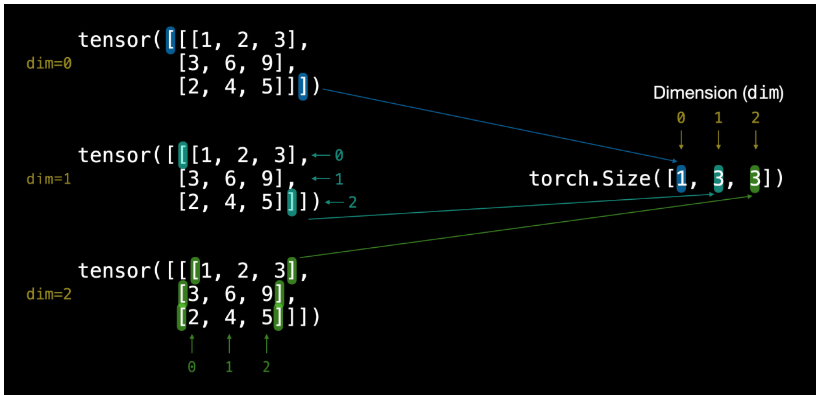

## PyTorch automatically stretches a smaller tensor so it can match a bigger tensor during operations.
## It does not copy data physically.
## It just behaves if it expanded it...

A = torch.rand(10, 5)
B = torch.rand(5)

A + B

shapes:
        A: (10, 5)
        B: (5,)

These are NOT the same shape.
But PyTorch allows it.

Why?
Because it applies broadcasting.

## It compares shapes form the RIGHT.

(10, 5)

(   5) => this is what pytorch see.

5 v 5 => ok

10 v (nothing)... in PyTorch when a dimention is missing it treats it as 1.
so this becomes =>
    (10, 5)
    (1, 5)

now broadcasting stretches:

    (1, 5) → (10, 5)

# BUTTTT................

## Now when it comes to from the right corner we come inside to out of a tensor.

## [[[1,2,3], [4,5,6]]]

## shape is => (1, 2, 3)

## 1 block, 2 rows, 3 columns

### Torch.reshape()

Simple note: Changes how elements are arranged into rows and columns without changing the number of elements.

import torch

x = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])

y = torch.reshape(x, (3, 2))

print(y)
# tensor([[1, 2],
#         [3, 4],
#         [5, 6]])


Remember: The number of elements stays the same: 2 x 3 = 3 x 2 = 6.
You can also write x.reshape(3, 2).

### Tensor.view() — Change the shape using a view

Simple note: 
        Gives you a different-shaped view of the same underlying data, when the tensor's memory layout permits it.


x = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])

y = x.view(3, 2)

The result looks like the reshape() example.

The important difference is that view() requires a compatible memory layout. reshape() is more flexible: it may return a view or make a copy if necessary.

Remember: Both change the shape, but view() specifically returns a view.


In [3]:
x = torch.tensor([1, 2, 3, 4, 5, 6])

y = x.reshape(2, 3)

print(y, x)

tensor([[1, 2, 3],
        [4, 5, 6]]) tensor([1, 2, 3, 4, 5, 6])


In [7]:
y[0, 0] = 100

print(y, x)

tensor([[100,   1,   2],
        [  3,   4,   5]]) tensor([100,   1,   2,   3,   4,   5])


In .reshape()

The number of elements must remain the same.

6 = 2 x 3 = 3 x 2 = 1 x 6

## Using `-1` in PyTorch `reshape()`

### What does `-1` mean?

`-1` tells PyTorch to automatically calculate the missing dimension.

**Formula:**

Unknown dimension = Total elements / Product of known dimensions

### Example

```python
import torch

x = torch.arange(12)

y = x.reshape(2, 2, -1)

print(y.shape)
# torch.Size([2, 2, 3])
```

**Explanation:**

- Total elements = 12
- Known dimensions = 2 and 2
- Product of known dimensions = 2 × 2 = 4
- Unknown dimension = 12 / 4 = 3

Therefore:

`reshape(2, 2, -1)` → `(2, 2, 3)`

### Important Rules

1. Only one `-1` is allowed.
2. Total number of elements must remain unchanged.
3. The missing dimension is calculated automatically.
4. The calculated dimension must be a valid whole number.

**Remember:** `-1` means "PyTorch, figure out this dimension for me."

In [5]:
w = torch.arange(6)

z = w.view(2, 3)

print(w, z)

tensor([0, 1, 2, 3, 4, 5]) tensor([[0, 1, 2],
        [3, 4, 5]])


In [6]:
z[0, 0] = 100

print(w, z)

tensor([100,   1,   2,   3,   4,   5]) tensor([[100,   1,   2],
        [  3,   4,   5]])


# PyTorch Notes — reshape() vs view()

## 1. What is `reshape()`?

`reshape()` changes the shape of a tensor without changing its total number of elements.

### Example

```python
import torch

x = torch.arange(6)

y = x.reshape(2, 3)

print(y)
```

**Output:**

```text
tensor([[0, 1, 2],
        [3, 4, 5]])
```

- Original shape: `(6,)`
- New shape: `(2, 3)`
- Total elements: 6

**Important:** The total number of elements must remain unchanged.

For example:

```python
x.reshape(3, 2)  # Valid: 3 × 2 = 6
x.reshape(1, 6)  # Valid: 1 × 6 = 6
x.reshape(2, 4)  # Error: 2 × 4 = 8
```

## 2. Using `-1` with `reshape()`

`-1` tells PyTorch to automatically calculate the missing dimension.

### Example

```python
x = torch.arange(12)

y = x.reshape(2, 2, -1)

print(y.shape)
# torch.Size([2, 2, 3])
```

**Calculation:**

- Total elements = 12
- Known dimensions = 2 and 2
- Product = 2 × 2 = 4
- Missing dimension = 12 / 4 = 3

Therefore:

`reshape(2, 2, -1)` → `(2, 2, 3)`

**Rules:**

- Only one `-1` is allowed.
- The total number of elements must remain unchanged.
- The inferred dimension must be valid.

## 3. What is `view()`?

`view()` changes how a tensor's data is represented without copying its underlying storage.

The new tensor shares memory with the original tensor.

### Example

```python
x = torch.arange(6)

y = x.view(2, 3)

print(y)
```

**Output:**

```text
tensor([[0, 1, 2],
        [3, 4, 5]])
```

Both `x` and `y` use the same underlying storage.

### What happens if we modify `y`?

```python
y[0, 0] = 99

print(x)
# tensor([99, 1, 2, 3, 4, 5])
```

The original tensor changes because both tensors share the same data.

**Key point:** `view()` never copies data to satisfy a requested shape. If the requested shape is incompatible with the tensor's memory layout, it raises an error.

## 4. What is the difference between `reshape()` and `view()`?

Both methods change a tensor's shape, but they handle memory differently.

| Feature | `view()` | `reshape()` |
|---|---|---|
| Changes tensor shape | Yes | Yes |
| Can share memory | Yes | Yes |
| Can create a copy | No | Yes |
| Can handle incompatible layouts by copying | No | Yes |

### The main difference

**`view()`**

- Always shares underlying storage.
- Never copies data.
- Raises an error if the requested shape cannot be represented as a view.

**`reshape()`**

- Shares memory when possible.
- Creates a copy when necessary.
- Is generally more flexible.

## 5. Example: Both share memory

```python
x = torch.arange(6)

a = x.view(2, 3)
b = x.reshape(2, 3)

b[0, 0] = 100

print(x)
# tensor([100, 1, 2, 3, 4, 5])
```

**Why?**

In this example, `reshape()` does not need to copy the data.

Both `a` and `b` share the underlying storage with `x`.

Therefore, modifying `b` also modifies `x`.

## 6. Example: `view()` fails but `reshape()` works

First, create a tensor.

```python
x = torch.arange(12).reshape(3, 4)

print(x)
```

**Output:**

```text
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
```

Transpose the tensor.

```python
t = x.T

print(t)
```

**Output:**

```text
tensor([[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]])
```

`x.T` swaps the rows and columns.

It creates a transposed view without physically rearranging the underlying data.

The resulting tensor is non-contiguous.

### Try `view()`

```python
a = t.view(2, 6)
# RuntimeError
```

**Why does it fail?**

The requested shape cannot be represented using the existing memory layout and strides.

Since `view()` cannot copy data, it raises an error.

### Try `reshape()`

```python
b = t.reshape(2, 6)

print(b)
```

**Output:**

```text
tensor([[ 0,  4,  8,  1,  5,  9],
        [ 2,  6, 10,  3,  7, 11]])
```

This works because `reshape()` creates a copy in this case.

### Verify that a copy was created

```python
b[0, 0] = 99

print(t[0, 0])
# tensor(0)
```

The original tensor remains unchanged because `b` has separate storage.

## 7. Memory Sharing vs Copying

### Case A: Shared memory

```python
x = torch.arange(6)
y = x.reshape(2, 3)

y[0, 0] = 50

print(x)
# tensor([50, 1, 2, 3, 4, 5])
```

`reshape()` reused the original memory.

**Result:** Modifying `y` affects `x`.

### Case B: Copied memory

```python
x = torch.arange(12).reshape(3, 4)

t = x.T
y = t.reshape(2, 6)

y[0, 0] = 50

print(t[0, 0])
# tensor(0)
```

`reshape()` created a copy.

**Result:** Modifying `y` does not affect `t`.

### Golden Rule

**If `reshape()` makes a copy, changes to the result do not affect the original tensor.**

**If `reshape()` shares memory, changes to the result can affect the original tensor.**

## 8. Simple Analogy — Library Books

Imagine 12 books stored on a shelf.

**`view()` — Same books, different reading instructions**

- Does not duplicate any books.
- Changes how you interpret their arrangement.
- Changing a book affects the original collection.
- If the requested arrangement cannot be represented without copying, it fails.

**`reshape()` — Reuse the books or make copies**

- First tries to reuse the original books.
- If that arrangement is impossible using the existing memory layout, it makes a separate copy.
- When a copy is made, changing it does not affect the original books.

## 9. Which one should I use?

**Use `reshape()` when:**

- You simply want to change a tensor's shape.
- You don't specifically require shared memory.
- You want PyTorch to handle incompatible memory layouts automatically.

**Use `view()` when:**

- You specifically need a view sharing the same underlying storage.
- You understand that the tensor's memory layout supports the requested shape.

**Important:** Never assume `reshape()` always shares memory or always copies.

## 10. Final Summary

- `reshape()` changes a tensor's shape while keeping the same number of elements.
- `view()` changes a tensor's shape without copying data.
- `reshape()` may share memory or create a copy.
- `view()` always shares underlying storage.
- `view()` can fail when the requested shape is incompatible with the tensor's memory layout.
- `reshape()` can handle such cases by copying.
- `-1` allows PyTorch to calculate one missing dimension automatically.
- Shared memory means modifications can affect the original tensor.
- Copied memory means modifications to the copy do not affect the original.

**Remember:**

`view()` = Reuse the same data, without copying.

`reshape()` = Reuse the data if possible; otherwise, copy it.

if makes a copy, changes are doing on the copied data. So original data wont affect.